# Analisi Stray Light con Background ConsDB e Valutazione Impatto (LVV-T956-a)
Questo notebook implementa l'analisi quantitativa e la fotometria calibrata della luce diffusa (*stray light* / *tape*), adottando la strategia del test di conformità Rubin **LVV-T956-a**:

1. **Background e Sky Noise ufficiali da ConsDB**:
   - Lettura diretta dei valori di `sky_bg` e `sky_noise` dalla tabella `cdb_lsstcam.ccdvisit1_quicklook` per ciascun CCD della visita, evitando stime empiriche o fit polinomiali soggetti a over-fitting dell'artefatto.
   - Costruzione del mosaico 2D geometricamente allineato di background e rumore di cielo.
2. **Download concorrente dal Butler**: Scaricamento a 10 worker paralleli e caching su disco.
3. **Selezione interattiva a 4 click**: Metodo originale a latenza zero tramite `splot.plot`.
4. **Stima dell'Impatto sul Piano Focale (Requisito LSR-REQ-0093-V-10)**:
   - Valutazione dell'ampiezza della feature rispetto al rumore di fondo cielo (criterio $\ge 1/3 \,\sigma_{\text{sky}}$).
   - Misura dell'area impattata (in arcmin² e deg²) e della frazione percentuale rispetto alla superficie totale del piano focale di LSSTCam (~9.6 deg²), verificando il rispetto del limite del $< 1\%$.
5. **Verifica su regione di cielo vuoto**: Misura della Surface Brightness assoluta in mag/arcsec² e test di accuratezza del background ConsDB.


In [28]:
%matplotlib inline
%matplotlib widget

import os
import threading
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.path import Path
from scipy.spatial import ConvexHull
from tqdm import tqdm

# Rubin Science Pipelines
import lsst.afw.math as afwMath
from lsst.afw.math import binImage
import lsst.afw.image as afwImage
from lsst.daf.butler import Butler
from lsst.pipe.tasks.visualizeVisit import VisualizeMosaicExpConfig, VisualizeMosaicExpTask
from lsst.summit.utils.utils import getCameraFromInstrumentName
from lsst.afw.cameraGeom import FOCAL_PLANE
import lsst.summit.utils.plotting as splot
from lsst.summit.utils import ConsDbClient

# Photometry & background modeling (fallback)
from photutils.background import Background2D, MedianBackground
from astropy.stats import SigmaClip

# ==============================================================================
# COSTANTI FISICHE E DI CAMERA LSSTCAM
# ==============================================================================
PIXEL_SCALE_ARCSEC = 0.2                     # Scala pixel nativa (arcsec/pixel)
DEFAULT_BINNING = 8                          # Fattore di binning per il mosaico
NATIVE_PIXEL_AREA_ARCSEC2 = PIXEL_SCALE_ARCSEC ** 2
BINNED_PIXEL_AREA_ARCSEC2 = (PIXEL_SCALE_ARCSEC * DEFAULT_BINNING) ** 2

DEFAULT_MAX_WORKERS = 10                     # Numero di thread paralleli per il Butler
MIN_CELL_SIZE_PX = 150                       # Dimensione minima sottocella (pixel binnati)
IMAGE_VMIN_PERCENTILE = 5                    # Percentili di visualizzazione contrasto
IMAGE_VMAX_PERCENTILE = 95
PIXEL_DISPLAY_FIGSIZE = (15, 6)

# Specifiche del Piano Focale LSSTCam per l'analisi di impatto (LVV-T956-a)
LSSTCAM_N_SCIENCE_CCDS = 189                 # Numero di sensori scientifici
LSSTCAM_CCD_WIDTH_PX = 4000                  # Larghezza CCD in pixel nativi
LSSTCAM_CCD_HEIGHT_PX = 4072                 # Altezza CCD in pixel nativi
TOTAL_FP_AREA_ARCSEC2 = (
    LSSTCAM_N_SCIENCE_CCDS * LSSTCAM_CCD_WIDTH_PX * LSSTCAM_CCD_HEIGHT_PX * NATIVE_PIXEL_AREA_ARCSEC2
)
TOTAL_FP_AREA_DEG2 = TOTAL_FP_AREA_ARCSEC2 / (3600.0 ** 2)  # ~9.60 deg²

# Criterio di impatto Rubin (LSR-REQ-0093-V-10 / LVV-T956-a)
SKY_NOISE_IMPACT_FRAC = 1.0 / 3.0            # Soglia di ampiezza: 1/3 del rumore del cielo
MAX_ALLOWED_IMPACT_PERCENT = 1.0             # Percentuale massima di area impattata ammessa (< 1%)


In [29]:
# ==============================================================================
# FUNZIONI CORE GEOMETRICHE E FOTOMETRICHE
# ==============================================================================

def polygon_area(vertices):
    """Calcola l'area di un poligono 2D tramite formula dello shoelace."""
    if len(vertices) < 3:
        return 0.0
    x, y = vertices[:, 0], vertices[:, 1]
    return 0.5 * np.abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))


def build_pca_oriented_grid(polygon_points, min_cell_size=MIN_CELL_SIZE_PX):
    """
    Esegue la PCA sui vertici del poligono selezionato per determinare
    gli assi intrinseci della feature e costruisce la griglia orientata.
    """
    pts = np.asarray(polygon_points, dtype=float)
    if pts.shape[0] < 3:
        raise ValueError("Il poligono deve contenere almeno 3 vertici.")

    centroid = pts.mean(axis=0)
    centered = pts - centroid
    cov = centered.T @ centered
    eigvals, eigvecs = np.linalg.eigh(cov)
    order = np.argsort(eigvals)[::-1]
    basis = eigvecs[:, order]
    proj = centered @ basis

    x_min, x_max = proj[:, 0].min(), proj[:, 0].max()
    y_min, y_max = proj[:, 1].min(), proj[:, 1].max()

    p0 = centroid + np.array([x_min, y_max]) @ basis.T
    p1 = centroid + np.array([x_min, y_min]) @ basis.T
    p2 = centroid + np.array([x_max, y_min]) @ basis.T
    p3 = centroid + np.array([x_max, y_max]) @ basis.T

    len_u = np.linalg.norm(p1 - p0)
    len_v = np.linalg.norm(p3 - p0)
    n_u = max(1, int(len_u // min_cell_size))
    n_v = max(1, int(len_v // min_cell_size))

    is_u_longest = len_u >= len_v
    us = np.linspace(0, 1, n_u + 1)
    vs = np.linspace(0, 1, n_v + 1)
    grid_pts = np.empty((n_u + 1, n_v + 1, 2))
    for iu, u in enumerate(us):
        for iv, v in enumerate(vs):
            grid_pts[iu, iv] = (
                (1 - u) * (1 - v) * p0
                + u * (1 - v) * p1
                + u * v * p2
                + (1 - u) * v * p3
            )

    cells = []
    for iu in range(n_u):
        for iv in range(n_v):
            cell_corners = np.array([
                grid_pts[iu, iv],
                grid_pts[iu + 1, iv],
                grid_pts[iu + 1, iv + 1],
                grid_pts[iu, iv + 1],
            ])
            cells.append({
                "iu": iu,
                "iv": iv,
                "corners": cell_corners
            })

    grid_meta = {
        "n_u": n_u,
        "n_v": n_v,
        "is_u_longest": is_u_longest,
        "longest_axis": "u" if is_u_longest else "v",
        "short_axis": "v" if is_u_longest else "u",
        "n_along_long": n_u if is_u_longest else n_v,
        "n_along_short": n_v if is_u_longest else n_u,
    }
    return cells, grid_meta


def measure_subcells_photometry(image, bkg_array, skynoise_array, cells, zp_calib, native_pixel_area=NATIVE_PIXEL_AREA_ARCSEC2):
    """
    Estrae la fotometria locale per ogni sottocella con metriche ConsDB:
    calcola mediane grezze, fondo ConsDB, rumore ConsDB, flusso netto,
    surface brightness netta e rapporto segnale/rumore (SNR).
    """
    ny, nx = image.shape
    subpoly_results = []

    for cell in cells:
        corners = cell["corners"]
        min_x = max(int(np.floor(corners[:, 0].min())), 0)
        max_x = min(int(np.ceil(corners[:, 0].max())), nx)
        min_y = max(int(np.floor(corners[:, 1].min())), 0)
        max_y = min(int(np.ceil(corners[:, 1].max())), ny)

        if max_x <= min_x or max_y <= min_y:
            continue

        cell_path = Path(corners)
        yy_box, xx_box = np.mgrid[min_y:max_y, min_x:max_x]
        box_coords = np.vstack((xx_box.ravel(), yy_box.ravel())).T
        inside = cell_path.contains_points(box_coords).reshape(yy_box.shape)

        raw_box = image[min_y:max_y, min_x:max_x][inside]
        bkg_box = bkg_array[min_y:max_y, min_x:max_x][inside]
        noise_box = skynoise_array[min_y:max_y, min_x:max_x][inside]

        valid = np.isfinite(raw_box)
        vals = raw_box[valid]
        bkg_vals = bkg_box[valid] if np.any(valid) else np.array([])
        bkg_vals = bkg_vals[np.isfinite(bkg_vals)]
        noise_vals = noise_box[valid] if np.any(valid) else np.array([])
        noise_vals = noise_vals[np.isfinite(noise_vals)]

        n_px = vals.size
        if n_px > 0:
            median_raw = float(np.median(vals))
            median_sky = float(np.median(bkg_vals)) if bkg_vals.size else 0.0
            median_noise = float(np.median(noise_vals)) if noise_vals.size else 1.0
            net_adu = median_raw - median_sky
            ratio = median_raw / median_sky if median_sky > 0 else np.nan
            snr = net_adu / median_noise if median_noise > 0 else np.nan
            sb_net = (
                zp_calib - 2.5 * np.log10(net_adu / native_pixel_area)
                if net_adu > 0 and np.isfinite(zp_calib) else np.nan
            )
        else:
            median_raw = median_sky = median_noise = net_adu = ratio = snr = sb_net = np.nan

        subpoly_results.append({
            "iu": cell["iu"],
            "iv": cell["iv"],
            "corners": corners,
            "n_px": n_px,
            "median_raw_adu": median_raw,
            "median_sky_adu": median_sky,
            "median_noise_adu": median_noise,
            "net_adu": net_adu,
            "ratio": ratio,
            "snr": snr,
            "sb_net": sb_net,
        })

    return subpoly_results


def filter_connected_feature(subpoly_results, grid_meta, threshold_factor=1.01, connectivity=4, max_polygon_sides=8):
    """
    Filtra le celle con contrasto >= threshold_factor ed estrae la componente
    connessa principale (flood-fill) e il contorno convesso (ConvexHull).
    """
    n_u, n_v = grid_meta["n_u"], grid_meta["n_v"]
    candidate_grid = np.zeros((n_v, n_u), dtype=bool)

    candidates = []
    for res in subpoly_results:
        is_cand = (
            np.isfinite(res["median_raw_adu"])
            and np.isfinite(res["median_sky_adu"])
            and res["median_sky_adu"] > 0
            and res["median_raw_adu"] >= threshold_factor * res["median_sky_adu"]
        )
        res["is_candidate"] = is_cand
        if is_cand:
            candidate_grid[res["iv"], res["iu"]] = True
            candidates.append(res)

    valid_cells = []
    if candidates:
        seed = max(candidates, key=lambda r: r["net_adu"] if np.isfinite(r["net_adu"]) else -1e9)
        connected = {(seed["iv"], seed["iu"])}
        pending = [(seed["iv"], seed["iu"])]

        while pending:
            iv_cur, iu_cur = pending.pop()
            neighbors = (
                [(iv_cur - 1, iu_cur), (iv_cur + 1, iu_cur),
                 (iv_cur, iu_cur - 1), (iv_cur, iu_cur + 1)]
                if connectivity == 4 else
                [(iv_cur + dv, iu_cur + du)
                 for dv in (-1, 0, 1) for du in (-1, 0, 1)
                 if (dv, du) != (0, 0)]
            )
            for n_iv, n_iu in neighbors:
                if 0 <= n_iv < n_v and 0 <= n_iu < n_u and candidate_grid[n_iv, n_iu] and (n_iv, n_iu) not in connected:
                    connected.add((n_iv, n_iu))
                    pending.append((n_iv, n_iu))

        valid_cells = [r for r in candidates if (r["iv"], r["iu"]) in connected]

    if valid_cells:
        corners_stack = np.vstack([r["corners"] for r in valid_cells])
        feature_poly = corners_stack[ConvexHull(corners_stack).vertices]
        if len(feature_poly) > max_polygon_sides:
            keep = np.linspace(0, len(feature_poly) - 1, max_polygon_sides, dtype=int)
            feature_poly = feature_poly[keep]
    else:
        feature_poly = np.empty((0, 2))

    return valid_cells, feature_poly, candidates


In [30]:
# ==============================================================================
# SELEZIONE VISITE E CONNESSIONE AL BUTLER
# ==============================================================================

# Visite di interesse (esposizioni con artefatto di stray light)
visits = [
    2025072000093,
    2026031000208,
    2026031200632,
    2026042700129,
]

# Indice della visita da analizzare
visit_idx = 3
current_visit = visits[visit_idx]
print(f"Visita selezionata per l'analisi: {current_visit} (indice {visit_idx} di {len(visits)})")

# Connessione al Butler Gen3
repo = "main"
coll = ["u/ataranto/lsst_outputs"]
butler = Butler(config=repo, instrument="LSSTCam")
print("Butler Gen3 connesso con successo.")


Visita selezionata per l'analisi: 2026042700129 (indice 3 di 4)
Butler Gen3 connesso con successo.


In [31]:
# ==============================================================================
# CONNESSIONE A CONSDB ED ESTRAZIONE SKY METRICS (COME DA SNIPPET UTENTE)
# ==============================================================================

vscode = True

if vscode == True:
    URL = "https://usdf-rsp.slac.stanford.edu/consdb"  # for vscode
    tk = os.environ["CONSDB_TOKEN"]  # set in .env (see README)
    cdb_client = ConsDbClient(URL, token=tk)
else:
    URL = "http://consdb-pq.consdb:8080/consdb"
    os.environ["no_proxy"] = os.environ.get("no_proxy", "") + ",.consdb"
    tk = None
    cdb_client = ConsDbClient(URL, token=tk)

print(f"Connessione a ConsDB ({URL})...")

query_consdb = f"""
    SELECT q.sky_bg, q.sky_noise, v.ccdvisit_id, v.visit_id, v.detector 
    FROM cdb_lsstcam.ccdvisit1 AS v, cdb_lsstcam.ccdvisit1_quicklook AS q
    WHERE v.visit_id = {current_visit} AND q.ccdvisit_id = v.ccdvisit_id
"""

consdb_bg_dict = {}
consdb_noise_dict = {}

try:
    ccd_table = cdb_client.query(query_consdb)

    def _to_clean_float(val):
        if val is None:
            return np.nan
        try:
            if hasattr(val, "mask") and bool(val.mask):
                return np.nan
        except Exception:
            pass
        try:
            f = float(val)
            return f if np.isfinite(f) else np.nan
        except (ValueError, TypeError):
            return np.nan

    # Conversione sicura in dizionari indicizzati per detector (gestendo None / NaN / masked)
    for row in ccd_table:
        try:
            det = int(row["detector"])
        except (ValueError, TypeError, KeyError):
            continue

        bg_val = _to_clean_float(row.get("sky_bg") if hasattr(row, "get") else row["sky_bg"])
        noise_val = _to_clean_float(row.get("sky_noise") if hasattr(row, "get") else row["sky_noise"])

        if not np.isnan(bg_val):
            consdb_bg_dict[det] = bg_val
        if not np.isnan(noise_val):
            consdb_noise_dict[det] = noise_val

    bg_vals = [v for v in consdb_bg_dict.values() if np.isfinite(v)]
    noise_vals = [v for v in consdb_noise_dict.values() if np.isfinite(v)]
    print(f"ConsDB: recuperate metriche valide per {len(consdb_bg_dict)} detector (su {len(ccd_table)} righe query):")
    if bg_vals:
        print(f"  - sky_bg:    mediana = {np.nanmedian(bg_vals):.2f} ADU (min = {np.nanmin(bg_vals):.2f}, max = {np.nanmax(bg_vals):.2f})")
    else:
        print("  - sky_bg:    nessun valore numerico valido trovato.")
    if noise_vals:
        print(f"  - sky_noise: mediana = {np.nanmedian(noise_vals):.2f} ADU (min = {np.nanmin(noise_vals):.2f}, max = {np.nanmax(noise_vals):.2f})")
    else:
        print("  - sky_noise: nessun valore numerico valido trovato.")

except Exception as err:
    print(f"ATTENZIONE: Connessione ConsDB non riuscita ({err}).")
    print("Verrà utilizzata la stima fotometrica di fallback dal Butler / Background2D.")


Connessione a ConsDB (https://usdf-rsp.slac.stanford.edu/consdb)...
ConsDB: recuperate metriche valide per 189 detector (su 193 righe query):
  - sky_bg:    mediana = 4189.55 ADU (min = -0.07, max = 4632.80)
  - sky_noise: mediana = 68.90 ADU (min = 4.92, max = 166.09)


In [32]:
# ==============================================================================
# CARICAMENTO PARALLELO CCD (10 WORKER) E COSTRUZIONE MOSAICI CON CACHE
# ==============================================================================

_thread_local = threading.local()

def _get_worker_butler(repo_name, instrument_name):
    """Restituisce un'istanza Butler thread-local per accesso concorrente sicuro."""
    if not hasattr(_thread_local, 'butler'):
        _thread_local.butler = Butler(config=repo_name, instrument=instrument_name)
    return _thread_local.butler


def _fetch_and_bin_single_detector(args):
    """Worker parallelo: estrae da Butler, maschera e binna l'immagine del CCD."""
    det_id, visit, collections, repo_name, binning, bad_mask_names = args
    try:
        local_butler = _get_worker_butler(repo_name, 'LSSTCam')
        dataId = {"instrument": "LSSTCam", "exposure": visit, "detector": det_id}
        im = local_butler.get("post_isr_image", dataId=dataId, collections=collections)

        bad_mask_bit = im.mask.getPlaneBitMask(bad_mask_names)
        msk = (im.mask.array.astype(int) & bad_mask_bit) != 0
        im.getMaskedImage().image.array[msk] = np.nan

        binned = binImage(im.getMaskedImage(), binning)
        return det_id, binned
    except Exception:
        return det_id, None


def load_or_build_mosaics_with_consdb(
    butler, visit, collections, consdb_bg_map, consdb_noise_map,
    binning=DEFAULT_BINNING, max_workers=DEFAULT_MAX_WORKERS,
    cache_dir="../outputs/img_e_data", force_reload=False
):
    """
    Carica o costruisce i mosaici 2D per:
    1. Immagine grezza post-ISR
    2. Modello di background ConsDB (allineato geometricamente pixel per pixel)
    3. Mappa di sky noise ConsDB (in ADU per pixel binnato)
    """
    os.makedirs(cache_dir, exist_ok=True)
    cache_path = os.path.join(cache_dir, f"mosaic_consdb_{visit}_bin{binning}.npz")

    if os.path.exists(cache_path) and not force_reload:
        print(f"Caricamento rapido dalla cache locale: {cache_path}")
        data = np.load(cache_path)
        return data["image"], data["bkg_array"], data["skynoise_array"], list(data["detector_ids"])

    print(f"Estrazione PARALLELA dal Butler per la visita {visit} ({max_workers} worker, binning={binning})...")
    camera = getCameraFromInstrumentName('LSSTCam')
    detects = [i for i in range(117, 190) if i != 122]
    bad_mask_names = ["NO_DATA", "DETECTED", "DETECTED_NEGATIVE", "SAT", "BAD", "INTRP", "CR"]

    tasks = [
        (det_id, visit, collections, repo, binning, bad_mask_names)
        for det_id in detects
    ]

    binned_dict = {}
    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        futures = [executor.submit(_fetch_and_bin_single_detector, t) for t in tasks]
        for fut in tqdm(as_completed(futures), total=len(futures), desc=f"Download parallelo CCD ({max_workers} worker)"):
            det_id, binned_im = fut.result()
            if binned_im is not None:
                binned_dict[det_id] = binned_im

    ids = sorted(binned_dict.keys())
    binned_images = [binned_dict[i] for i in ids]

    mosConfig = VisualizeMosaicExpConfig()
    mosConfig.binning = binning
    mosTask = VisualizeMosaicExpTask(config=mosConfig)

    # 1. Mosaico immagine grezza
    print(f"Assemblaggio mosaico del piano focale per {len(binned_images)} sensori...")
    mosaic_array = mosTask.run(binned_images, camera, inputIds=ids).outputData.array

    # 2. Mosaico background ConsDB (geometria identica)
    valid_bgs = [v for v in consdb_bg_map.values() if np.isfinite(v)]
    valid_noises = [v for v in consdb_noise_map.values() if np.isfinite(v)]
    global_med_bg = np.nanmedian(valid_bgs) if len(valid_bgs) > 0 else np.nan
    global_med_noise = np.nanmedian(valid_noises) if len(valid_noises) > 0 else 10.0

    bkg_images = []
    noise_images = []
    for det_id, b_im in zip(ids, binned_images):
        bg_val = consdb_bg_map.get(det_id, np.nan)
        if bg_val is None or not np.isfinite(bg_val):
            bg_val = global_med_bg if np.isfinite(global_med_bg) else float(np.nanmedian(b_im.image.array))

        noise_val = consdb_noise_map.get(det_id, np.nan)
        if noise_val is None or not np.isfinite(noise_val):
            noise_val = global_med_noise if np.isfinite(global_med_noise) else max(1.0, float(np.nanstd(b_im.image.array)))

        b_noise_val = noise_val / binning  # errore standard per pixel binnato

        bg_clone = b_im.clone()
        bg_clone.image.array[:, :] = bg_val
        bkg_images.append(bg_clone)

        noise_clone = b_im.clone()
        noise_clone.image.array[:, :] = b_noise_val
        noise_images.append(noise_clone)

    bkg_array = mosTask.run(bkg_images, camera, inputIds=ids).outputData.array
    skynoise_array = mosTask.run(noise_images, camera, inputIds=ids).outputData.array

    np.savez_compressed(
        cache_path,
        image=mosaic_array,
        bkg_array=bkg_array,
        skynoise_array=skynoise_array,
        detector_ids=np.array(ids)
    )
    print(f"Tutti i mosaici (Image, ConsDB Bkg, ConsDB Noise) salvati in cache: {cache_path}")
    return mosaic_array, bkg_array, skynoise_array, ids

image, bkg_array, skynoise_array, detector_ids = load_or_build_mosaics_with_consdb(
    butler=butler,
    visit=current_visit,
    collections=coll,
    consdb_bg_map=consdb_bg_dict,
    consdb_noise_map=consdb_noise_dict,
    binning=DEFAULT_BINNING,
    max_workers=DEFAULT_MAX_WORKERS
)

print(f"Mosaico immagine:  dimensione {image.shape}, mediana = {np.nanmedian(image):.2f} ADU")
print(f"Background ConsDB: mediana = {np.nanmedian(bkg_array):.2f} ADU")
print(f"Sky Noise ConsDB:  mediana = {np.nanmedian(skynoise_array):.2f} ADU / px binnato")


Caricamento rapido dalla cache locale: ./img_e_data/mosaic_consdb_2026042700129_bin8.npz
Mosaico immagine:  dimensione (7927, 7939), mediana = 4203.41 ADU
Background ConsDB: mediana = 4192.85 ADU
Sky Noise ConsDB:  mediana = 8.64 ADU / px binnato


In [33]:
# ==============================================================================
# MASCHERAMENTO VIGNETTATURA E MAPPE DI RESIDUO NETTO / SNR
# ==============================================================================

ny, nx = image.shape
xCen, yCen = nx / 2.0, ny / 2.0
rad_vignette = (nx + ny) / 4.0
yy, xx = np.mgrid[:ny, :nx]
vignet_mask = np.hypot(xx - xCen, yy - yCen) >= rad_vignette

# Mascheramento comune su tutti i layer
image[vignet_mask] = np.nan
bkg_array[vignet_mask] = np.nan
skynoise_array[vignet_mask] = np.nan

# 1. Immagine netta (con sottrazione diretta del background ConsDB)
net_image = image - bkg_array

# 2. Immagine in unità di rumore di cielo (SNR)
snr_image = net_image / skynoise_array

print("Mappe calcolate con successo:")
print(f"  - Flusso netto (Raw - ConsDB Bkg): mediana = {np.nanmedian(net_image):.2f} ADU, max = {np.nanmax(net_image):.2f} ADU")
print(f"  - Rapporto SNR (Net / SkyNoise):    mediana = {np.nanmedian(snr_image):.3f} σ,  max = {np.nanmax(snr_image):.3f} σ")


Mappe calcolate con successo:
  - Flusso netto (Raw - ConsDB Bkg): mediana = 1.50 ADU, max = 58960.44 ADU
  - Rapporto SNR (Net / SkyNoise):    mediana = 0.174 σ,  max = 6351.169 σ


Click 4 times on the image to define the corners of your polygon.


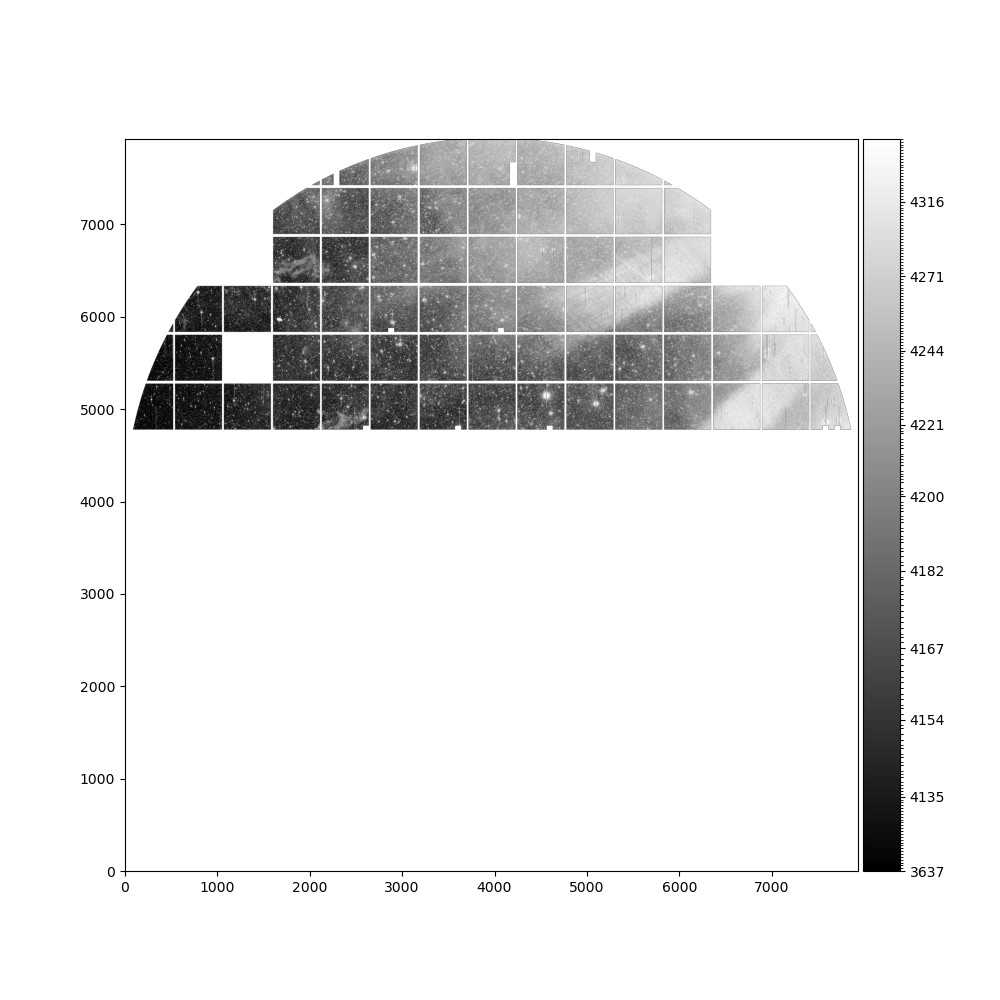

In [34]:
# ==============================================================================
# SELEZIONE INTERATTIVA DELLA ROI (ORIGINALE A 4 CLICK)
# ==============================================================================

fig = plt.figure(figsize=(10, 10))
cb = splot.plot(image, stretch='ccs', figure=fig)
ax = fig.axes[0]  # Usa l'asse creato da splot.plot()

polygon_points = []

def onclick(event):
    if event.inaxes != ax:
        return
    # Registra vertice e disegna punto rosso
    polygon_points.append((event.xdata, event.ydata))
    ax.plot(event.xdata, event.ydata, 'ro')
    fig.canvas.draw()

    # Al 4° click chiude il poligono in giallo e disconnette il listener
    if len(polygon_points) == 4:
        poly = Polygon(polygon_points, closed=True, fill=False, edgecolor='yellow', linewidth=2)
        ax.add_patch(poly)
        fig.canvas.draw()
        fig.canvas.mpl_disconnect(cid)

        # Costruzione della maschera booleana veloce
        global poly_mask
        poly_path = Path(polygon_points)
        ny, nx = image.shape
        pts = np.asarray(polygon_points, dtype=float)
        min_x = max(int(np.floor(pts[:, 0].min())), 0)
        max_x = min(int(np.ceil(pts[:, 0].max())), nx)
        min_y = max(int(np.floor(pts[:, 1].min())), 0)
        max_y = min(int(np.ceil(pts[:, 1].max())), ny)
        yy_box, xx_box = np.mgrid[min_y:max_y, min_x:max_x]
        box_coords = np.vstack((xx_box.ravel(), yy_box.ravel())).T
        poly_mask = np.zeros((ny, nx), dtype=bool)
        poly_mask[min_y:max_y, min_x:max_x] = poly_path.contains_points(box_coords).reshape(yy_box.shape)
        print("Poligono confermato con 4 punti! Maschera creata.")

cid = fig.canvas.mpl_connect('button_press_event', onclick)
print("Click 4 times on the image to define the corners of your polygon.")


In [35]:
# ==============================================================================
# ASSOCIAZIONE DETECTOR SUL PIANO FOCALE E CALIBRAZIONE FOTOMETRICA
# ==============================================================================

# if 'polygon_points' not in globals() or len(polygon_points) < 4:
#     print("Nessun poligono tracciato interattivamente: utilizzo coordinate salvate di default.")
#     polygon_points = [(1500, 1200), (3200, 2100), (3100, 2400), (1400, 1500)]
#     poly_path = Path(polygon_points)
#     ny, nx = image.shape
#     yy, xx = np.mgrid[:ny, :nx]
#     coords = np.vstack((xx.ravel(), yy.ravel())).T
#     poly_mask = poly_path.contains_points(coords).reshape(ny, nx)

camera = getCameraFromInstrumentName('LSSTCam')
detector_corners = {
    det.getId(): np.array([[pt.getX(), pt.getY()] for pt in det.getCorners(FOCAL_PLANE)])
    for det in camera
}

poly_pts_arr = np.array(polygon_points)
scale_factor = np.abs(np.min(detector_corners[0])) / (image.shape[1] / 2.0)
poly_pts_mm = (poly_pts_arr - (image.shape[1] / 2.0)) * scale_factor

det_ids_in_poly = []
poly_path_mm = Path(poly_pts_mm)
for det_id, corners in detector_corners.items():
    det_path = Path(corners)
    min_c, max_c = np.min(poly_pts_mm, axis=0), np.max(poly_pts_mm, axis=0)
    gx, gy = np.meshgrid(np.linspace(min_c[0], max_c[0], 50), np.linspace(min_c[1], max_c[1], 50))
    g_pts = np.vstack([gx.ravel(), gy.ravel()]).T
    inside = poly_path_mm.contains_points(g_pts)
    if np.any(det_path.contains_points(g_pts[inside])):
        det_ids_in_poly.append(det_id)

print(f"Sensori fisici attraversati ({len(det_ids_in_poly)}):", det_ids_in_poly)

# Calcolo parallelo del punto zero fotometrico medio (zp_calib) per i detector interessati
def _fetch_photocalib(det):
    try:
        local_butler = _get_worker_butler(repo, 'LSSTCam')
        dataId = {'instrument': 'LSSTCam', 'visit': current_visit, 'detector': det}
        exp = local_butler.get('preliminary_visit_image', dataId=dataId, collections=coll)
        return exp.photoCalib.instFluxToMagnitude(1.0)
    except Exception:
        return None

valid_dets = [d for d in det_ids_in_poly if d not in [120, 121, 122]]
with ThreadPoolExecutor(max_workers=DEFAULT_MAX_WORKERS) as executor:
    results = list(executor.map(_fetch_photocalib, valid_dets))
mag_zps = [r for r in results if r is not None]

zp_calib = float(np.nanmedian(mag_zps)) if mag_zps else 31.0
print(f"Punto zero fotometrico medio calibrato (zp_calib): {zp_calib:.4f} mag")

poly_sum = float(np.nansum(image[poly_mask]))
num_px = int(np.count_nonzero(np.isfinite(image[poly_mask])))
inst_flux_mean = poly_sum / num_px if num_px > 0 else 0.0
mean_sb = zp_calib - 2.5 * np.log10(inst_flux_mean / BINNED_PIXEL_AREA_ARCSEC2) if inst_flux_mean > 0 else np.nan
print(f"Area totale ROI: {num_px} px ({num_px * BINNED_PIXEL_AREA_ARCSEC2:.1f} arcsec²)")
print(f"Luminosita superficiale grezza media: {mean_sb:.3f} mag / arcsec²")


Sensori fisici attraversati (14): [135, 136, 138, 139, 140, 142, 143, 147, 150, 151, 152, 180, 181, 182]


/sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.1.0/share/eups/Linux64/obs_base/g00893bd134+caafe9eba2/python/lsst/obs/base/formatters/fitsExposure.py:798: FutureWarning: Summary fields [centroidDiffShapeletsVsSlotMedian, nShapeletsStar, psfAdaptiveIncludeThresholdMultiplier, psfAdaptiveThresholdValue, refCatSourceDensity, shapeletsCoeffs, shapeletsIqScore, shapeletsOnlyIqScore, shapeletsStarEMedian, shapeletsStarUnNormalizedEMedian, starComa1Median, starComa2Median, starE41Median, starE42Median, starKurtosisMedian, starTrefoil1Median, starTrefoil2Median] not recognized by this software version; ignoring them.
  result = self.reader.read(**self.checked_parameters, dtype=self.storageClass_dtype)


Punto zero fotometrico medio calibrato (zp_calib): 31.5758 mag
Area totale ROI: 1482678 px (3795655.7 arcsec²)
Luminosita superficiale grezza media: 23.514 mag / arcsec²


In [36]:
# ==============================================================================
# TASSELLAZIONE PCA ED ESTRAZIONE FOTOMETRICA CON METRICHE CONSDB
# ==============================================================================

# 1. Griglia orientata lungo l'asse maggiore della feature
subcells, grid_meta = build_pca_oriented_grid(polygon_points, min_cell_size=MIN_CELL_SIZE_PX)
print(f"Griglia orientata PCA: {grid_meta['n_u']} x {grid_meta['n_v']} ({len(subcells)} sottocelle)")
print(f"Asse principale: {grid_meta['longest_axis']} ({grid_meta['n_along_long']} passi)")

# 2. Fotometria locale a singolo passaggio con background ConsDB
subpoly_results = measure_subcells_photometry(
    image=image,
    bkg_array=bkg_array,
    skynoise_array=skynoise_array,
    cells=subcells,
    zp_calib=zp_calib,
    native_pixel_area=NATIVE_PIXEL_AREA_ARCSEC2
)

# 3. Diagnostica contrasto e rapporto con lo Sky Noise ConsDB
snrs = np.array([r["snr"] for r in subpoly_results if np.isfinite(r["snr"])])
net_adus = np.array([r["net_adu"] for r in subpoly_results if np.isfinite(r["net_adu"])])
print("-" * 65)
print(f"Diagnostica segnale netto vs Sky Noise ConsDB:")
print(f"  Rapporto Net / SkyNoise (SNR): mediana = {np.median(snrs):.3f} σ | max = {np.max(snrs):.3f} σ")
print(f"  Flusso netto locale:           mediana = {np.median(net_adus):.2f} ADU | max = {np.max(net_adus):.2f} ADU")
print("-" * 65)


Griglia orientata PCA: 4 x 21 (84 sottocelle)
Asse principale: v (21 passi)
-----------------------------------------------------------------
Diagnostica segnale netto vs Sky Noise ConsDB:
  Rapporto Net / SkyNoise (SNR): mediana = 0.501 σ | max = 7.315 σ
  Flusso netto locale:           mediana = 4.32 ADU | max = 65.19 ADU
-----------------------------------------------------------------


In [37]:
# ==============================================================================
# SELEZIONE MORFOLOGICA, COMPONENTE CONNESSA E FOTOMETRIA INTEGRATA
# ==============================================================================

# Soglia relativa configurabile (es. +0.8% sopra il background ConsDB)
SKY_EXCESS_PERCENT = 0.8
SKY_EXCESS_FACTOR = 1.0 + (SKY_EXCESS_PERCENT / 100.0)
CONNECTIVITY = 4

valid_cells, feature_polygon, candidates = filter_connected_feature(
    subpoly_results=subpoly_results,
    grid_meta=grid_meta,
    threshold_factor=SKY_EXCESS_FACTOR,
    connectivity=CONNECTIVITY,
    max_polygon_sides=8
)

feature_area_binned_px = polygon_area(feature_polygon) if len(feature_polygon) >= 3 else 0.0
feature_area_arcsec2 = feature_area_binned_px * BINNED_PIXEL_AREA_ARCSEC2
feature_area_arcmin2 = feature_area_arcsec2 / 3600.0

valid_net_flux_adu = np.array([
    r["net_adu"] * r["n_px"] * (DEFAULT_BINNING ** 2)
    for r in valid_cells
])
total_net_flux_adu = float(np.sum(valid_net_flux_adu)) if valid_net_flux_adu.size else 0.0
integrated_mag = (
    zp_calib - 2.5 * np.log10(total_net_flux_adu)
    if total_net_flux_adu > 0 else np.nan
)

print("=" * 65)
print("       RISULTATO MORFOLOGIA STRAY LIGHT E FOTOMETRIA")
print("=" * 65)
print(f"Soglia contrasto ConsDB:                      +{SKY_EXCESS_PERCENT:.2f}%")
print(f"Sottocelle selezionate (componente connessa): {len(valid_cells)} / {len(subpoly_results)}")
print(f"Area feature stimata:                         {feature_area_arcsec2:.2f} arcsec² ({feature_area_arcmin2:.4f} arcmin²)")
print(f"Flusso netto integrato (ConsDB subtracted):    {total_net_flux_adu:.3f} ADU nativi")
print(f"Magnitudine integrata netta:                  {integrated_mag:.4f} mag")
print("=" * 65)


       RISULTATO MORFOLOGIA STRAY LIGHT E FOTOMETRIA
Soglia contrasto ConsDB:                      +0.80%
Sottocelle selezionate (componente connessa): 1 / 84
Area feature stimata:                         60556.51 arcsec² (16.8213 arcmin²)
Flusso netto integrato (ConsDB subtracted):    73487490.469 ADU nativi
Magnitudine integrata netta:                  11.9103 mag


   ANALISI IMPATTO EFFETTIVO SUL PIANO FOCALE (DENTRO LA REGIONE ROI)
Visita analizzata:                          2026042700129
Pixel totali validi nella ROI disegnata:    1482678 px binnati (1054.35 arcmin²)
---------------------------------------------------------------------------
CRITERIO PRINCIPALE RICHIESTO (Ratio >= 1.0 σ_sky):
  - Pixel compromessi (>= 1.0 σ):           701945 px binnati (44,924,480 nativi)
  - Area effettivamente compromessa:         499.161 arcmin² (0.138656 deg²)
  - PERCENTUALE PIANO FOCALE COMPROMESSA:    1.45933%
  - Frazione della sola ROI a >= 1.0 σ:      47.34%
---------------------------------------------------------------------------
CONFRONTO CON ALTRE SOGLIE DI RUMORE (DENTRO LA ROI):
  - Soglia specifica Rubin (>= 1/3 σ):       1.77122% del piano focale (851965 px)
  - Soglia 2.0 σ:                            1.08295% del piano focale (520903 px)
  - Soglia 3.0 σ:                            0.82271% del piano focale (395728 px)
-------------------

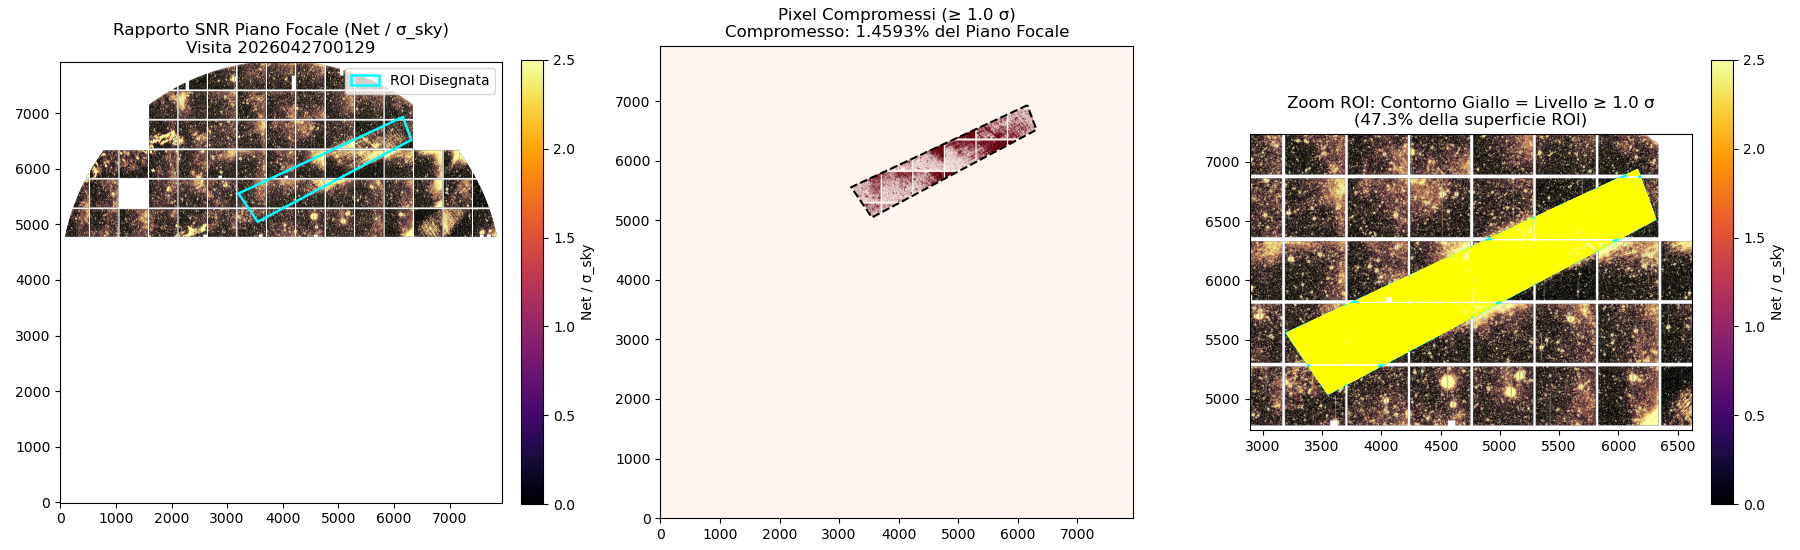

In [38]:
# ==============================================================================
# VALUTAZIONE IMPATTO SUL PIANO FOCALE: PIXEL CON RATIO >= 1 SIGMA NELLA REGIONE
# ==============================================================================

# Filtro sui pixel validi all'interno del poligono disegnato dall'utente
valid_pixels = poly_mask & np.isfinite(snr_image)
n_poly_valid_px = int(np.count_nonzero(valid_pixels))

# 1. Maschera dei pixel compromessi con Ratio (Net / Sky Noise) >= 1.0 sigma dentro la ROI
mask_1sigma = valid_pixels & (snr_image >= 1.0)
n_1sigma_binned_px = int(np.count_nonzero(mask_1sigma))
n_1sigma_native_px = n_1sigma_binned_px * (DEFAULT_BINNING ** 2)

# Calcolo area compromessa a >= 1.0 sigma
area_1sigma_arcsec2 = n_1sigma_binned_px * BINNED_PIXEL_AREA_ARCSEC2
area_1sigma_arcmin2 = area_1sigma_arcsec2 / 3600.0
area_1sigma_deg2 = area_1sigma_arcsec2 / (3600.0 ** 2)

# Percentuale di PIANO FOCALE effettivamente compromessa (LSSTCam ~9.60 deg² totali)
fp_compromised_percent = (area_1sigma_deg2 / TOTAL_FP_AREA_DEG2) * 100.0

# Frazione interna alla ROI disegnata che supera 1.0 sigma
roi_compromised_percent = (n_1sigma_binned_px / max(1, n_poly_valid_px)) * 100.0 if n_poly_valid_px > 0 else 0.0

# 2. Confronto con la specifica Rubin di riferimento (>= 1/3 sigma) e altre soglie
mask_third_sigma = valid_pixels & (snr_image >= (1.0 / 3.0))
mask_2sigma = valid_pixels & (snr_image >= 2.0)
mask_3sigma = valid_pixels & (snr_image >= 3.0)

n_third_binned = int(np.count_nonzero(mask_third_sigma))
n_2sigma_binned = int(np.count_nonzero(mask_2sigma))
n_3sigma_binned = int(np.count_nonzero(mask_3sigma))

fp_percent_third = (n_third_binned * BINNED_PIXEL_AREA_ARCSEC2 / TOTAL_FP_AREA_ARCSEC2) * 100.0
fp_percent_2sigma = (n_2sigma_binned * BINNED_PIXEL_AREA_ARCSEC2 / TOTAL_FP_AREA_ARCSEC2) * 100.0
fp_percent_3sigma = (n_3sigma_binned * BINNED_PIXEL_AREA_ARCSEC2 / TOTAL_FP_AREA_ARCSEC2) * 100.0

# Distribuzione statistica del rapporto SNR dentro la ROI disegnata
snr_in_roi = snr_image[valid_pixels]
snr_median_roi = float(np.nanmedian(snr_in_roi)) if snr_in_roi.size else 0.0
snr_max_roi = float(np.nanmax(snr_in_roi)) if snr_in_roi.size else 0.0
snr_p90_roi = float(np.nanpercentile(snr_in_roi, 90)) if snr_in_roi.size else 0.0

print("=" * 75)
print("   ANALISI IMPATTO EFFETTIVO SUL PIANO FOCALE (DENTRO LA REGIONE ROI)")
print("=" * 75)
print(f"Visita analizzata:                          {current_visit}")
print(f"Pixel totali validi nella ROI disegnata:    {n_poly_valid_px} px binnati ({(n_poly_valid_px * BINNED_PIXEL_AREA_ARCSEC2 / 3600.0):.2f} arcmin²)")
print("-" * 75)
print("CRITERIO PRINCIPALE RICHIESTO (Ratio >= 1.0 σ_sky):")
print(f"  - Pixel compromessi (>= 1.0 σ):           {n_1sigma_binned_px} px binnati ({n_1sigma_native_px:,} nativi)")
print(f"  - Area effettivamente compromessa:         {area_1sigma_arcmin2:.3f} arcmin² ({area_1sigma_deg2:.6f} deg²)")
print(f"  - PERCENTUALE PIANO FOCALE COMPROMESSA:    {fp_compromised_percent:.5f}%")
print(f"  - Frazione della sola ROI a >= 1.0 σ:      {roi_compromised_percent:.2f}%")
print("-" * 75)
print("CONFRONTO CON ALTRE SOGLIE DI RUMORE (DENTRO LA ROI):")
print(f"  - Soglia specifica Rubin (>= 1/3 σ):       {fp_percent_third:.5f}% del piano focale ({n_third_binned} px)")
print(f"  - Soglia 2.0 σ:                            {fp_percent_2sigma:.5f}% del piano focale ({n_2sigma_binned} px)")
print(f"  - Soglia 3.0 σ:                            {fp_percent_3sigma:.5f}% del piano focale ({n_3sigma_binned} px)")
print("-" * 75)
print(f"Statistiche SNR dentro la ROI: Mediana = {snr_median_roi:.2f} σ, 90° perc = {snr_p90_roi:.2f} σ, Max = {snr_max_roi:.2f} σ")
print("=" * 75)

# Visualizzazione a 3 pannelli per la massima chiarezza diagnostica
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Pannello 1: Mappa globale SNR del piano focale con la ROI
im0 = axes[0].imshow(snr_image, origin="lower", cmap="inferno", vmin=0, vmax=2.5)
axes[0].set_title(f"Rapporto SNR Piano Focale (Net / σ_sky)\nVisita {current_visit}")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04, label="Net / σ_sky")
if len(polygon_points) >= 4:
    axes[0].add_patch(Polygon(polygon_points, closed=True, fill=False, edgecolor="cyan", linewidth=1.8, label="ROI Disegnata"))
axes[0].legend(loc="upper right")

# Pannello 2: Mappa globale dei soli pixel compromessi (>= 1.0 σ) dentro la ROI
im1 = axes[1].imshow(mask_1sigma, origin="lower", cmap="Reds")
axes[1].set_title(f"Pixel Compromessi (≥ 1.0 σ)\nCompromesso: {fp_compromised_percent:.4f}% del Piano Focale")
if len(polygon_points) >= 4:
    axes[1].add_patch(Polygon(polygon_points, closed=True, fill=False, edgecolor="black", linewidth=1.5, linestyle="--"))

# Pannello 3: Zoom dettagliato sulla ROI disegnata con contorno a 1.0 sigma
if len(polygon_points) >= 4:
    xs = [p[0] for p in polygon_points]
    ys = [p[1] for p in polygon_points]
    pad = max(20, int(0.1 * max(max(xs) - min(xs), max(ys) - min(ys))))
    x0, x1 = max(0, int(min(xs) - pad)), min(snr_image.shape[1], int(max(xs) + pad))
    y0, y1 = max(0, int(min(ys) - pad)), min(snr_image.shape[0], int(max(ys) + pad))
    
    zoom_snr = snr_image[y0:y1, x0:x1]
    im2 = axes[2].imshow(zoom_snr, origin="lower", cmap="inferno", extent=[x0, x1, y0, y1], vmin=0, vmax=2.5)
    axes[2].add_patch(Polygon(polygon_points, closed=True, fill=False, edgecolor="cyan", linewidth=2.0))
    
    zoom_mask_1sigma = mask_1sigma[y0:y1, x0:x1]
    axes[2].contour(zoom_mask_1sigma, levels=[0.5], colors=["yellow"], linewidths=[1.5], extent=[x0, x1, y0, y1])
    axes[2].set_title(f"Zoom ROI: Contorno Giallo = Livello ≥ 1.0 σ\n({roi_compromised_percent:.1f}% della superficie ROI)")
    plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04, label="Net / σ_sky")
else:
    axes[2].text(0.5, 0.5, "Nessuna ROI selezionata", ha="center", va="center")

plt.tight_layout()
plt.show()
